In [11]:
import pandas as pd
from pathlib import Path
import ast

root = Path("../rqs/random_selection")
output_file = root / "median_prompts.csv"

def normalize_individual(value):

    # Already a list
    if isinstance(value, list):
        return value

    # Handle numeric scalar
    if isinstance(value, (int, float)) and not pd.isna(value):
        return [int(value)]

    # Convert to string
    value = str(value).strip()

    # First try Python literal parsing
    try:
        parsed = ast.literal_eval(value)

        if isinstance(parsed, (list, tuple)):
            return [int(x) for x in parsed]

        if isinstance(parsed, (int, float)):
            return [int(parsed)]

    except (ValueError, SyntaxError):
        pass
        
    try:
        return [
            int(x.strip())
            for x in value.split(",")
            if x.strip()
        ]
    except ValueError:
        raise ValueError(
            f"Could not parse Individual value: {value}"
        )

result_files = list(
    root.glob("*/models/*/*/logs/fewshot_results_macro_f1.csv")
)

print(f"Found {len(result_files)} result files.")



all_results = []

for file_path in result_files:

    # Skip the meta-llama-1 folder
    if "meta-llama-1" in file_path.parts:
        continue

    repo = file_path.parents[4].name
    model_provider = file_path.parents[2].name
    model = file_path.parents[1].name

    df = pd.read_csv(file_path)

    required_columns = [
        "Repo",
        "FewShot_Count",
        "Trial",
        "Individual",
        "Macro_F1",
    ]

    missing = [
        col for col in required_columns
        if col not in df.columns
    ]

    if missing:
        raise ValueError(
            f"Missing columns in {file_path}: {missing}"
        )

    df = df[required_columns].copy()

    # Store model information
    df["Model_Provider"] = model_provider
    df["Model"] = model

    all_results.append(df)


if not all_results:
    raise RuntimeError("No result files were found.")


results = pd.concat(all_results, ignore_index=True)

selected_rows = []

group_columns = [
    "Repo",
    "Model_Provider",
    "Model",
    "FewShot_Count",
]

for group_keys, group in results.groupby(
    group_columns,
    sort=True
):

    group = group.copy()

    # Median Macro-F1 among the 20 random prompts
    median_f1 = group["Macro_F1"].median()

    # Find observed prompt closest to the median
    group["_distance_to_median"] = (
        group["Macro_F1"] - median_f1
    ).abs()

    group = group.sort_values(
        by=[
            "_distance_to_median",
            "Trial",
        ],
        kind="stable",
    )

    selected = group.iloc[0].copy()

    # Convert Individual to vector/list
    selected["Individual"] = normalize_individual(
        selected["Individual"]
    )

    selected_rows.append(selected)


median_prompts = pd.DataFrame(selected_rows)


# ---------------------------------------------------------
# Sanity check:
# number of elements in Individual should equal k
# ---------------------------------------------------------

for idx, row in median_prompts.iterrows():

    individual = row["Individual"]
    k = int(row["FewShot_Count"])

    if len(individual) != k:
        print(
            f"WARNING: "
            f"Repo={row['Repo']}, "
            f"Model={row['Model']}, "
            f"k={k}, "
            f"Individual={individual} "
            f"contains {len(individual)} elements."
        )

median_prompts["Individual"] = median_prompts[
    "Individual"
].apply(
    lambda x: "[" + ", ".join(map(str, x)) + "]"
)


# ---------------------------------------------------------
# Final column order
# ---------------------------------------------------------

median_prompts = median_prompts[
    [
        "Repo",
        "Model_Provider",
        "Model",
        "FewShot_Count",
        "Trial",
        "Individual",
        "Macro_F1",
    ]
].sort_values(
    [
        "Repo",
        "Model",
        "FewShot_Count",
    ]
)


# ---------------------------------------------------------
# Save
# ---------------------------------------------------------

median_prompts.to_csv(
    output_file,
    index=False
)

print(
    f"\nSaved {len(median_prompts)} "
    f"median prompts to:\n{output_file}"
)

print("\nPreview:")
print(
    median_prompts.head(20).to_string(index=False)
)

Found 25 result files.

Saved 240 median prompts to:
..\rqs\random_selection\median_prompts.csv

Preview:
           Repo Model_Provider                    Model  FewShot_Count  Trial                                                                                                                                                     Individual  Macro_F1
bitcoin_bitcoin     meta-llama    Llama-3.1-8B-Instruct              1     11                                                                                                                                                          [191]  0.717284
bitcoin_bitcoin     meta-llama    Llama-3.1-8B-Instruct              2      3                                                                                                                                                     [137, 190]  0.749817
bitcoin_bitcoin     meta-llama    Llama-3.1-8B-Instruct              3     16                                                                            

FILES FOUND
Found 20 CSV files.

..\rqs\determinism\bitcoin_bitcoin\models\google\gemma-3-12b-it\logs\fewshot_results_macro_f1.csv
..\rqs\determinism\bitcoin_bitcoin\models\meta-llama\Llama-3.1-8B-Instruct\logs\fewshot_results_macro_f1.csv
..\rqs\determinism\bitcoin_bitcoin\models\mistralai\Mistral-7B-Instruct-v0.3\logs\fewshot_results_macro_f1.csv
..\rqs\determinism\bitcoin_bitcoin\models\Qwen\Qwen2.5-7B-Instruct\logs\fewshot_results_macro_f1.csv
..\rqs\determinism\facebook_react\models\google\gemma-3-12b-it\logs\fewshot_results_macro_f1.csv
..\rqs\determinism\facebook_react\models\meta-llama\Llama-3.1-8B-Instruct\logs\fewshot_results_macro_f1.csv
..\rqs\determinism\facebook_react\models\mistralai\Mistral-7B-Instruct-v0.3\logs\fewshot_results_macro_f1.csv
..\rqs\determinism\facebook_react\models\Qwen\Qwen2.5-7B-Instruct\logs\fewshot_results_macro_f1.csv
..\rqs\determinism\microsoft_vscode\models\google\gemma-3-12b-it\logs\fewshot_results_macro_f1.csv
..\rqs\determinism\microsoft_vscod

,Repo,Model,FewShot_Count,Trial,Individual,Original_Macro_F1,Repeat_Mean_F1,Repeat_Median_F1,Repeat_SD,Repeat_Min_F1,Repeat_Max_F1,Repeat_Range,Repeat_IQR,Repeat_MAD_Median,N_Unique_F1,Zero_Variance,AbsDiff_Original_Mean,AbsDiff_Original_Median,RelativeAbsDiff_Original_Mean_pct,MaxAbsDiff_From_Original,Exact_Original_Count,Exact_Original_Rate,Original_Inside_Repeat_Range,N_Repeats
0,bitcoin_bitcoin,Qwen/Qwen2.5-7B-Instruct,1,7,[760],0.762271,0.762271,0.762271,0.000000,0.762271,0.762271,0.000000,0.000000,0.000000,1,True,0.000000,0.000000,0.000000,0.000000,10,1.000000,True,10
1,bitcoin_bitcoin,Qwen/Qwen2.5-7B-Instruct,2,15,"[370, 591]",0.744277,0.754284,0.758572,0.006905,0.744277,0.758572,0.014296,0.010722,0.004289,2,False,0.010007,0.014296,1.344527,0.014296,3,0.300000,True,10
2,bitcoin_bitcoin,Qwen/Qwen2.5-7B-Instruct,3,1,"[97, 355, 755]",0.765320,0.765320,0.765320,0.000000,0.765320,0.765320,0.000000,0.000000,0.000000,1,True,0.000000,0.000000,0.000000,0.000000,10,1.000000,True,10
3,bitcoin_bitcoin,Qwen/Qwen2.5-7B-Instruct,4,18,"[258, 556, 561, 816]",0.762271,0.742325,0.742325,0.000000,0.742325,0.742325,0.000000,0.000000,0.000000,1,True,0.019946,0.019946,2.616698,0.019946,0,0.000000,False,10
4,bitcoin_bitcoin,Qwen/Qwen2.5-7B-Instruct,6,4,"[65, 80, 469, 496, 700, 830]",0.767239,0.767239,0.767239,0.000000,0.767239,0.767239,0.000000,0.000000,0.000000,1,True,0.000000,0.000000,0.000000,0.000000,10,1.000000,True,10
5,bitcoin_bitcoin,Qwen/Qwen2.5-7B-Instruct,8,13,"[187, 226, 269, 280, 453, 613, 618, 818]",0.762452,0.751997,0.751997,0.004953,0.747298,0.756695,0.009398,0.009398,0.004699,2,False,0.010456,0.010456,1.371308,0.015154,0,0.000000,False,10
6,bitcoin_bitcoin,Qwen/Qwen2.5-7B-Instruct,10,7,"[31, 103, 184, 236, 309, 336, 605, 617, 650, 786]",0.775062,0.757604,0.757604,0.000000,0.757604,0.757604,0.000000,0.000000,0.000000,1,True,0.017458,0.017458,2.252443,0.017458,0,0.000000,False,10
7,bitcoin_bitcoin,Qwen/Qwen2.5-7B-Instruct,12,2,"[0, 193, 260, 261, 277, 345, 401, 476, 545, 55...",0.769332,0.764156,0.769332,0.006683,0.756391,0.769332,0.012941,0.012941,0.005176,2,False,0.005176,0.000000,0.672823,0.012941,6,0.600000,True,10
8,bitcoin_bitcoin,Qwen/Qwen2.5-7B-Instruct,16,0,"[17, 109, 111, 135, 172, 197, 209, 215, 229, 4...",0.769340,0.769340,0.769340,0.000000,0.769340,0.769340,0.000000,0.000000,0.000000,1,True,0.000000,0.000000,0.000000,0.000000,10,1.000000,True,10
9,bitcoin_bitcoin,Qwen/Qwen2.5-7B-Instruct,20,2,"[2, 29, 75, 99, 220, 269, 279, 343, 382, 388, ...",0.804991,0.813881,0.812910,0.003071,0.812910,0.822622,0.009712,0.000000,0.000971,2,False,0.008890,0.007919,1.104372,0.017631,0,0.000000,False,10



Saved:
..\rqs\determinism\analysis\determinism_per_configuration.csv

TOP 30: LARGEST VARIATION AMONG THE 10 REPEATS


,Repo,Model,FewShot_Count,Original_Macro_F1,Repeat_Mean_F1,Repeat_Median_F1,Repeat_SD,Repeat_Range,Repeat_Min_F1,Repeat_Max_F1,N_Unique_F1,Exact_Original_Count,Exact_Original_Rate,AbsDiff_Original_Mean,MaxAbsDiff_From_Original
76,facebook_react,meta-llama/Llama-3.1-8B-Instruct,6,0.620915,0.586580,0.580833,0.018853,0.069138,0.551777,0.620915,4,1,0.100000,0.034335,0.069138
165,opencv_opencv,google/gemma-3-12b-it,20,0.700509,0.710787,0.711967,0.013777,0.034712,0.688712,0.723424,3,4,0.400000,0.010278,0.022915
61,facebook_react,google/gemma-3-12b-it,2,0.702827,0.692567,0.702827,0.016520,0.034199,0.668627,0.702827,2,7,0.700000,0.010260,0.034199
73,facebook_react,meta-llama/Llama-3.1-8B-Instruct,2,0.615048,0.631021,0.623504,0.015550,0.033589,0.615048,0.648637,3,3,0.300000,0.015973,0.033589
86,facebook_react,mistralai/Mistral-7B-Instruct-v0.3,3,0.553241,0.579807,0.573752,0.012765,0.030275,0.573752,0.604027,2,0,0.000000,0.026566,0.050786
36,bitcoin_bitcoin,mistralai/Mistral-7B-Instruct-v0.3,1,0.564809,0.575428,0.579890,0.009720,0.029106,0.557875,0.586982,6,1,0.100000,0.010619,0.022173
78,facebook_react,meta-llama/Llama-3.1-8B-Instruct,10,0.677910,0.672090,0.677910,0.012270,0.029101,0.648810,0.677910,2,8,0.800000,0.005820,0.029101
239,tensorflow_tensorflow,mistralai/Mistral-7B-Instruct-v0.3,32,0.560784,0.560207,0.560784,0.007440,0.025206,0.544745,0.569951,5,5,0.500000,0.000577,0.016039
215,tensorflow_tensorflow,google/gemma-3-12b-it,32,0.656610,0.665181,0.667664,0.007474,0.023978,0.656610,0.680588,5,3,0.300000,0.008572,0.023978
92,facebook_react,mistralai/Mistral-7B-Instruct-v0.3,16,0.582420,0.596637,0.606115,0.012236,0.023696,0.582420,0.606115,2,4,0.400000,0.014217,0.023696



TOP 30: ORIGINAL RUN FARTHEST FROM REPEATED-RUN MEAN


,Repo,Model,FewShot_Count,Original_Macro_F1,Repeat_Mean_F1,Repeat_Median_F1,Repeat_SD,Repeat_Range,Repeat_Min_F1,Repeat_Max_F1,N_Unique_F1,Exact_Original_Count,Exact_Original_Rate,AbsDiff_Original_Mean,MaxAbsDiff_From_Original
76,facebook_react,meta-llama/Llama-3.1-8B-Instruct,6,0.620915,0.586580,0.580833,0.018853,0.069138,0.551777,0.620915,4,1,0.100000,0.034335,0.069138
62,facebook_react,google/gemma-3-12b-it,3,0.667061,0.695446,0.695446,0.000000,0.000000,0.695446,0.695446,1,0,0.000000,0.028386,0.028386
86,facebook_react,mistralai/Mistral-7B-Instruct-v0.3,3,0.553241,0.579807,0.573752,0.012765,0.030275,0.573752,0.604027,2,0,0.000000,0.026566,0.050786
91,facebook_react,mistralai/Mistral-7B-Instruct-v0.3,12,0.557634,0.534259,0.534259,0.000000,0.000000,0.534259,0.534259,1,0,0.000000,0.023375,0.023375
3,bitcoin_bitcoin,Qwen/Qwen2.5-7B-Instruct,4,0.762271,0.742325,0.742325,0.000000,0.000000,0.742325,0.742325,1,0,0.000000,0.019946,0.019946
22,bitcoin_bitcoin,google/gemma-3-12b-it,24,0.753794,0.735811,0.737197,0.004380,0.013851,0.723346,0.737197,2,0,0.000000,0.017983,0.030449
93,facebook_react,mistralai/Mistral-7B-Instruct-v0.3,20,0.578026,0.595555,0.599937,0.009238,0.021911,0.578026,0.599937,2,2,0.200000,0.017529,0.021911
6,bitcoin_bitcoin,Qwen/Qwen2.5-7B-Instruct,10,0.775062,0.757604,0.757604,0.000000,0.000000,0.757604,0.757604,1,0,0.000000,0.017458,0.017458
11,bitcoin_bitcoin,Qwen/Qwen2.5-7B-Instruct,32,0.785316,0.768985,0.769915,0.002940,0.009296,0.760619,0.769915,2,0,0.000000,0.016331,0.024697
73,facebook_react,meta-llama/Llama-3.1-8B-Instruct,2,0.615048,0.631021,0.623504,0.015550,0.033589,0.615048,0.648637,3,3,0.300000,0.015973,0.033589


... (9 outputs left out)

,FewShot_Count,N_Configurations,Mean_Repeat_SD,Median_Repeat_SD,Max_Repeat_SD,Mean_Repeat_Range,Median_Repeat_Range,Max_Repeat_Range,Mean_AbsDiff_Original_Mean,Median_AbsDiff_Original_Mean,Max_AbsDiff_Original_Mean,Zero_Variance_Rate,Exact_Original_Rate
0,1,20,0.003439,0.002142,0.011665,0.008626,0.006006,0.029106,0.003838,0.002788,0.013553,0.200000,0.505000
1,2,20,0.004155,0.003270,0.016520,0.009321,0.007868,0.034199,0.004365,0.003201,0.015973,0.250000,0.435000
2,3,20,0.001499,0.000000,0.012765,0.003864,0.000000,0.030275,0.005350,0.000846,0.028386,0.550000,0.545000
3,4,20,0.002487,0.001626,0.010039,0.005604,0.003997,0.021229,0.004220,0.001770,0.019946,0.400000,0.425000
4,6,20,0.003067,0.001974,0.018853,0.008978,0.004882,0.069138,0.004544,0.001197,0.034335,0.300000,0.455000
5,8,20,0.002828,0.002434,0.008051,0.007311,0.006034,0.019217,0.002877,0.001542,0.011933,0.250000,0.420000
6,10,20,0.002555,0.001882,0.012270,0.006382,0.005092,0.029101,0.004086,0.002577,0.017458,0.300000,0.450000
7,12,20,0.003052,0.003142,0.009033,0.007541,0.007527,0.023208,0.005162,0.003079,0.023375,0.300000,0.380000
8,16,20,0.002626,0.001765,0.012236,0.007171,0.004777,0.023696,0.004051,0.002911,0.014217,0.400000,0.470000
9,20,20,0.002677,0.001798,0.013777,0.007226,0.004557,0.034712,0.004487,0.002413,0.017529,0.350000,0.430000



SPEARMAN: FEW-SHOT COUNT vs INSTABILITY


,Repo,Model,Spearman_rho_k_SD,p_k_SD,Spearman_rho_k_Range,p_k_Range,Spearman_rho_k_OriginalDiff,p_k_OriginalDiff
9,microsoft_vscode,google/gemma-3-12b-it,0.713287,0.009202,0.797203,0.001900,0.636364,0.026097
18,tensorflow_tensorflow,meta-llama/Llama-3.1-8B-Instruct,0.647903,0.022709,0.505418,0.093697,0.010508,0.974145
10,microsoft_vscode,meta-llama/Llama-3.1-8B-Instruct,0.538462,0.070894,0.622378,0.030676,0.468531,0.124455
17,tensorflow_tensorflow,google/gemma-3-12b-it,0.510490,0.089914,0.524476,0.080019,0.111888,0.729195
16,tensorflow_tensorflow,Qwen/Qwen2.5-7B-Instruct,0.420316,0.173686,0.329247,0.296007,0.426573,0.166700
13,opencv_opencv,google/gemma-3-12b-it,0.297724,0.347291,0.360771,0.249283,0.150613,0.640335
14,opencv_opencv,meta-llama/Llama-3.1-8B-Instruct,0.258741,0.416775,0.605649,0.036880,0.174825,0.586824
0,bitcoin_bitcoin,Qwen/Qwen2.5-7B-Instruct,0.203248,0.526366,0.250066,0.433110,0.189475,0.555325
2,bitcoin_bitcoin,meta-llama/Llama-3.1-8B-Instruct,0.195781,0.541985,0.241307,0.449914,0.372877,0.232570
7,facebook_react,mistralai/Mistral-7B-Instruct-v0.3,0.050758,0.875516,-0.052253,0.871877,0.316909,0.315544



OVERALL CORRELATIONS
k vs Repeat SD:
rho = 0.0615, p = 3.4296e-01

k vs Repeat Range:
rho = 0.0931, p = 1.5029e-01

k vs |Original - Repeat Mean|:
rho = 0.0631, p = 3.2999e-01


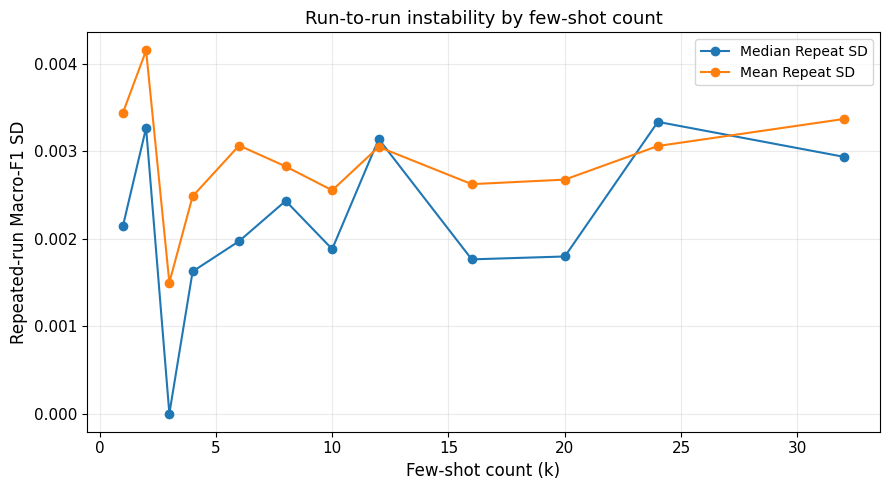

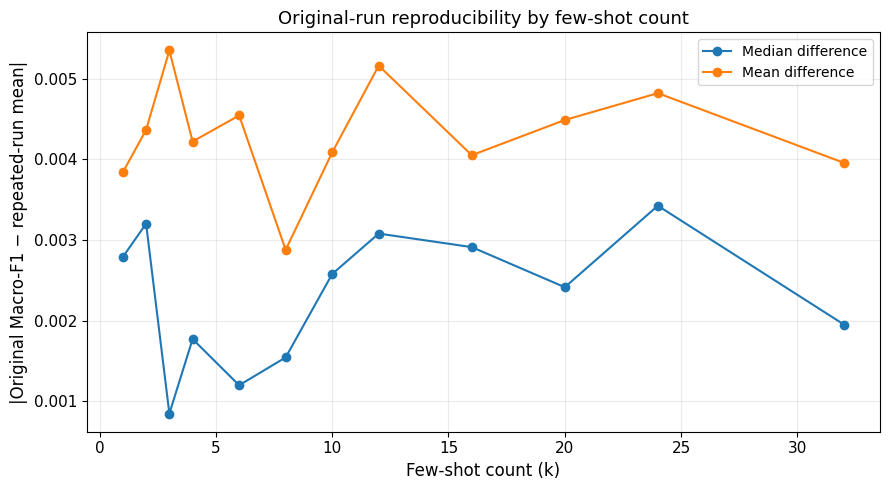


PAPER-LEVEL SUMMARY


,Repo,Model,Median Repeat SD,Max Repeat Range,Median |Original - Repeat Mean|,Max |Original - Repeat Mean|,Zero-Variance Configurations (%),Exact Original Reproduction (%)
0,bitcoin_bitcoin,Qwen/Qwen2.5-7B-Instruct,0.001231,0.014296,0.007950,0.019946,50.000000,41.666667
1,bitcoin_bitcoin,google/gemma-3-12b-it,0.000000,0.016669,0.000000,0.017983,83.333333,89.166667
2,bitcoin_bitcoin,meta-llama/Llama-3.1-8B-Instruct,0.000000,0.019985,0.000000,0.010189,66.666667,70.833333
3,bitcoin_bitcoin,mistralai/Mistral-7B-Instruct-v0.3,0.001925,0.029106,0.005164,0.010619,33.333333,37.500000
4,facebook_react,Qwen/Qwen2.5-7B-Instruct,0.000000,0.022589,0.000000,0.013553,66.666667,90.833333
5,facebook_react,google/gemma-3-12b-it,0.000000,0.034199,0.002259,0.028386,66.666667,66.666667
6,facebook_react,meta-llama/Llama-3.1-8B-Instruct,0.005901,0.069138,0.001866,0.034335,41.666667,77.500000
7,facebook_react,mistralai/Mistral-7B-Instruct-v0.3,0.000180,0.030275,0.004000,0.026566,50.000000,53.333333
8,microsoft_vscode,Qwen/Qwen2.5-7B-Instruct,0.001375,0.009748,0.002814,0.006442,0.000000,7.500000
9,microsoft_vscode,google/gemma-3-12b-it,0.002175,0.016424,0.001797,0.005562,0.000000,10.833333



OVERALL DETERMINISM SUMMARY
Total Repo × Model × k configurations: 240

Zero-variance configurations: 75/240 (31.25%)

Exact reproduction of original Macro-F1: 43.67%

Mean repeated-run SD: 0.002902
Median repeated-run SD: 0.002199
Maximum repeated-run range: 0.069138

Mean |Original - Repeat Mean|: 0.004313
Median |Original - Repeat Mean|: 0.002333

OUTPUT FILES
..\rqs\determinism\analysis\determinism_per_configuration.csv
..\rqs\determinism\analysis\determinism_by_repo_model.csv
..\rqs\determinism\analysis\determinism_by_model.csv
..\rqs\determinism\analysis\determinism_by_repository.csv
..\rqs\determinism\analysis\determinism_by_k.csv
..\rqs\determinism\analysis\determinism_k_correlations.csv
..\rqs\determinism\analysis\determinism_paper_summary.csv


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr


# =========================================================
# SETTINGS
# =========================================================

ROOT = Path("../rqs/determinism")

RESULT_FILENAME = "fewshot_results_macro_f1.csv"

# Number of repeated executions per selected prompt
EXPECTED_REPEATS = 10

# Where analysis results will be saved
OUTPUT_DIR = ROOT / "analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_rows", 300)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:.6f}")


# =========================================================
# 1. FIND ALL DETERMINISM RESULT FILES
# =========================================================

csv_files = sorted(ROOT.rglob(RESULT_FILENAME))

print("=" * 100)
print("FILES FOUND")
print("=" * 100)

print(f"Found {len(csv_files)} CSV files.\n")

for path in csv_files:
    print(path)

if not csv_files:
    raise FileNotFoundError(
        f"No '{RESULT_FILENAME}' files found under:\n{ROOT.resolve()}"
    )


# =========================================================
# 2. LOAD ALL FILES
# =========================================================

required_columns = {
    "Repo",
    "Model",
    "FewShot_Count",
    "Trial",
    "Repeat",
    "Individual",
    "Original_Macro_F1",
    "Macro_F1",
}

frames = []

for path in csv_files:

    df = pd.read_csv(path)

    missing = required_columns - set(df.columns)

    if missing:
        raise ValueError(
            f"\nFile:\n{path}\n"
            f"is missing columns:\n{sorted(missing)}"
        )

    df["Source_File"] = str(path)

    frames.append(df)


runs = pd.concat(frames, ignore_index=True)


# Convert numeric columns explicitly
runs["FewShot_Count"] = pd.to_numeric(
    runs["FewShot_Count"],
    errors="raise"
).astype(int)

runs["Trial"] = pd.to_numeric(
    runs["Trial"],
    errors="raise"
).astype(int)

runs["Repeat"] = pd.to_numeric(
    runs["Repeat"],
    errors="raise"
).astype(int)

runs["Original_Macro_F1"] = pd.to_numeric(
    runs["Original_Macro_F1"],
    errors="raise"
)

runs["Macro_F1"] = pd.to_numeric(
    runs["Macro_F1"],
    errors="raise"
)


print("\n" + "=" * 100)
print("LOADED DATA")
print("=" * 100)

print(f"Rows:            {len(runs):,}")
print(f"Repositories:    {runs['Repo'].nunique()}")
print(f"Models:          {runs['Model'].nunique()}")
print(
    f"Few-shot counts: "
    f"{sorted(runs['FewShot_Count'].unique())}"
)

print("\nRepositories:")
print(sorted(runs["Repo"].unique()))

print("\nModels:")
print(sorted(runs["Model"].unique()))


# =========================================================
# 3. VALIDATE EXPERIMENT
# =========================================================

GROUP_COLS = [
    "Repo",
    "Model",
    "FewShot_Count",
]


print("\n" + "=" * 100)
print("VALIDATION")
print("=" * 100)


# ---------------------------------------------------------
# Duplicate repeat IDs
# ---------------------------------------------------------

duplicate_repeats = (
    runs
    .groupby(GROUP_COLS + ["Repeat"])
    .size()
    .reset_index(name="N")
)

duplicate_repeats = duplicate_repeats[
    duplicate_repeats["N"] > 1
]

if len(duplicate_repeats) > 0:

    print("\nWARNING: duplicate repeat IDs found:")
    display(duplicate_repeats)

else:

    print("✓ No duplicate repeat IDs.")


# ---------------------------------------------------------
# Check exactly 10 repeated runs per configuration
# ---------------------------------------------------------

repeat_counts = (
    runs
    .groupby(GROUP_COLS)
    .agg(
        N_Rows=("Macro_F1", "size"),
        N_Repeats=("Repeat", "nunique"),
    )
    .reset_index()
)

bad_repeat_counts = repeat_counts[
    (repeat_counts["N_Rows"] != EXPECTED_REPEATS)
    |
    (repeat_counts["N_Repeats"] != EXPECTED_REPEATS)
]

if len(bad_repeat_counts) > 0:

    print(
        f"\nWARNING: configurations not containing "
        f"exactly {EXPECTED_REPEATS} repetitions:"
    )

    display(bad_repeat_counts)

else:

    print(
        f"✓ Every configuration contains exactly "
        f"{EXPECTED_REPEATS} repetitions."
    )


# ---------------------------------------------------------
# Original Macro-F1 must remain constant
# ---------------------------------------------------------

original_consistency = (
    runs
    .groupby(GROUP_COLS)["Original_Macro_F1"]
    .nunique()
    .reset_index(name="N_Original_F1")
)

bad_original = original_consistency[
    original_consistency["N_Original_F1"] != 1
]

if len(bad_original) > 0:

    print(
        "\nWARNING: Original_Macro_F1 changes "
        "within some configurations:"
    )

    display(bad_original)

else:

    print(
        "✓ Original Macro-F1 is constant "
        "within every configuration."
    )


# ---------------------------------------------------------
# Same prompt must be repeated
# ---------------------------------------------------------

prompt_consistency = (
    runs
    .groupby(GROUP_COLS)
    .agg(
        N_Trials=("Trial", "nunique"),
        N_Individuals=("Individual", "nunique"),
    )
    .reset_index()
)

bad_prompts = prompt_consistency[
    (prompt_consistency["N_Trials"] != 1)
    |
    (prompt_consistency["N_Individuals"] != 1)
]

if len(bad_prompts) > 0:

    print(
        "\nWARNING: prompt/trial changes "
        "within repeated evaluations:"
    )

    display(bad_prompts)

else:

    print(
        "Same prompt/trial used for all repetitions."
    )


# =========================================================
# 4. COMPUTE PER-CONFIGURATION METRICS
# =========================================================

def summarize_configuration(g):

    original_values = g[
        "Original_Macro_F1"
    ].unique()

    if len(original_values) != 1:
        raise ValueError(
            f"Multiple original Macro-F1 values found: "
            f"{original_values}"
        )

    original = float(
        original_values[0]
    )

    vals = g[
        "Macro_F1"
    ].to_numpy(dtype=float)


    # -----------------------------------------------------
    # Repeated-run central tendency
    # -----------------------------------------------------

    repeat_mean = np.mean(vals)

    repeat_median = np.median(vals)


    # -----------------------------------------------------
    # Repeated-run variability
    # -----------------------------------------------------

    repeat_min = np.min(vals)

    repeat_max = np.max(vals)

    repeat_range = (
        repeat_max
        -
        repeat_min
    )

    repeat_sd = (
        np.std(
            vals,
            ddof=1
        )
        if len(vals) > 1
        else 0.0
    )

    q1 = np.percentile(
        vals,
        25
    )

    q3 = np.percentile(
        vals,
        75
    )

    repeat_iqr = (
        q3
        -
        q1
    )

    # Mean absolute deviation from repeated-run median
    repeat_mad_median = np.mean(
        np.abs(
            vals
            -
            repeat_median
        )
    )

    n_unique = len(
        np.unique(vals)
    )

    zero_variance = np.allclose(
        vals,
        vals[0],
        rtol=0,
        atol=1e-12,
    )


    # -----------------------------------------------------
    # Original vs repeated runs
    # -----------------------------------------------------

    abs_diff_original_mean = abs(
        original
        -
        repeat_mean
    )

    abs_diff_original_median = abs(
        original
        -
        repeat_median
    )

    max_abs_diff_from_original = np.max(
        np.abs(
            vals
            -
            original
        )
    )


    # Relative difference between original and repeated mean
    if original != 0:

        relative_abs_diff_original_mean_pct = (
            abs_diff_original_mean
            /
            abs(original)
            *
            100
        )

    else:

        relative_abs_diff_original_mean_pct = np.nan


    # -----------------------------------------------------
    # Exact reproduction
    # -----------------------------------------------------

    exact_matches = np.isclose(
        vals,
        original,
        rtol=0,
        atol=1e-12,
    )

    exact_original_count = int(
        exact_matches.sum()
    )

    exact_original_rate = (
        exact_original_count
        /
        len(vals)
    )


    # -----------------------------------------------------
    # Does original fall inside repeated-run range?
    # -----------------------------------------------------

    original_inside_repeat_range = (
        original
        >= repeat_min - 1e-12
        and
        original
        <= repeat_max + 1e-12
    )


    return {
        "Trial":
            g["Trial"].iloc[0],

        "Individual":
            g["Individual"].iloc[0],

        "Original_Macro_F1":
            original,

        # Repeated-run central tendency
        "Repeat_Mean_F1":
            repeat_mean,

        "Repeat_Median_F1":
            repeat_median,

        # Repeated-run stability
        "Repeat_SD":
            repeat_sd,

        "Repeat_Min_F1":
            repeat_min,

        "Repeat_Max_F1":
            repeat_max,

        "Repeat_Range":
            repeat_range,

        "Repeat_IQR":
            repeat_iqr,

        "Repeat_MAD_Median":
            repeat_mad_median,

        "N_Unique_F1":
            n_unique,

        "Zero_Variance":
            bool(zero_variance),

        # Original vs repeated runs
        "AbsDiff_Original_Mean":
            abs_diff_original_mean,

        "AbsDiff_Original_Median":
            abs_diff_original_median,

        "RelativeAbsDiff_Original_Mean_pct":
            relative_abs_diff_original_mean_pct,

        "MaxAbsDiff_From_Original":
            max_abs_diff_from_original,

        "Exact_Original_Count":
            exact_original_count,

        "Exact_Original_Rate":
            exact_original_rate,

        "Original_Inside_Repeat_Range":
            original_inside_repeat_range,

        "N_Repeats":
            len(vals),
    }


# ---------------------------------------------------------
# Apply to every Repo × Model × k
# ---------------------------------------------------------

summary_rows = []

for (
    repo,
    model,
    k
), group in runs.groupby(
    GROUP_COLS,
    sort=True
):

    stats = summarize_configuration(
        group
    )

    stats["Repo"] = repo
    stats["Model"] = model
    stats["FewShot_Count"] = k

    summary_rows.append(
        stats
    )


config_summary = pd.DataFrame(
    summary_rows
)


# Put important identifiers first
first_columns = [
    "Repo",
    "Model",
    "FewShot_Count",
    "Trial",
    "Individual",
]

remaining_columns = [
    col
    for col in config_summary.columns
    if col not in first_columns
]

config_summary = config_summary[
    first_columns
    +
    remaining_columns
]


config_summary = (
    config_summary
    .sort_values(
        [
            "Repo",
            "Model",
            "FewShot_Count",
        ]
    )
    .reset_index(drop=True)
)


print("\n" + "=" * 100)
print("PER-CONFIGURATION RESULTS")
print("=" * 100)

display(
    config_summary
)


# =========================================================
# 5. SAVE FULL PER-CONFIGURATION TABLE
# =========================================================

config_output = (
    OUTPUT_DIR
    /
    "determinism_per_configuration.csv"
)

config_summary.to_csv(
    config_output,
    index=False
)

print(
    f"\nSaved:\n{config_output}"
)


# =========================================================
# 6. MOST UNSTABLE CONFIGURATIONS
# =========================================================

important_cols = [
    "Repo",
    "Model",
    "FewShot_Count",
    "Original_Macro_F1",
    "Repeat_Mean_F1",
    "Repeat_Median_F1",
    "Repeat_SD",
    "Repeat_Range",
    "Repeat_Min_F1",
    "Repeat_Max_F1",
    "N_Unique_F1",
    "Exact_Original_Count",
    "Exact_Original_Rate",
    "AbsDiff_Original_Mean",
    "MaxAbsDiff_From_Original",
]


print("\n" + "=" * 100)
print("TOP 30: LARGEST VARIATION AMONG THE 10 REPEATS")
print("=" * 100)

display(
    config_summary
    .sort_values(
        "Repeat_Range",
        ascending=False
    )
    [important_cols]
    .head(30)
)


print("\n" + "=" * 100)
print("TOP 30: ORIGINAL RUN FARTHEST FROM REPEATED-RUN MEAN")
print("=" * 100)

display(
    config_summary
    .sort_values(
        "AbsDiff_Original_Mean",
        ascending=False
    )
    [important_cols]
    .head(30)
)


print("\n" + "=" * 100)
print("TOP 30: LARGEST SINGLE DEVIATION FROM ORIGINAL")
print("=" * 100)

display(
    config_summary
    .sort_values(
        "MaxAbsDiff_From_Original",
        ascending=False
    )
    [important_cols]
    .head(30)
)


# =========================================================
# 7. SUMMARY BY REPOSITORY × MODEL
# =========================================================

repo_model_summary = (
    config_summary
    .groupby(
        [
            "Repo",
            "Model",
        ]
    )
    .agg(

        N_Configurations=(
            "FewShot_Count",
            "size"
        ),

        # ---------------------------------------------
        # Repeat stability
        # ---------------------------------------------

        Mean_Repeat_SD=(
            "Repeat_SD",
            "mean"
        ),

        Median_Repeat_SD=(
            "Repeat_SD",
            "median"
        ),

        Max_Repeat_SD=(
            "Repeat_SD",
            "max"
        ),

        Mean_Repeat_Range=(
            "Repeat_Range",
            "mean"
        ),

        Median_Repeat_Range=(
            "Repeat_Range",
            "median"
        ),

        Max_Repeat_Range=(
            "Repeat_Range",
            "max"
        ),

        # ---------------------------------------------
        # Original vs reruns
        # ---------------------------------------------

        Mean_AbsDiff_Original_Mean=(
            "AbsDiff_Original_Mean",
            "mean"
        ),

        Median_AbsDiff_Original_Mean=(
            "AbsDiff_Original_Mean",
            "median"
        ),

        Max_AbsDiff_Original_Mean=(
            "AbsDiff_Original_Mean",
            "max"
        ),

        Mean_MaxAbsDiff_From_Original=(
            "MaxAbsDiff_From_Original",
            "mean"
        ),

        Max_MaxAbsDiff_From_Original=(
            "MaxAbsDiff_From_Original",
            "max"
        ),

        # ---------------------------------------------
        # Intuitive reproducibility measures
        # ---------------------------------------------

        Zero_Variance_Configurations=(
            "Zero_Variance",
            "sum"
        ),

        Exact_Original_Evaluation_Rate=(
            "Exact_Original_Rate",
            "mean"
        ),

        Original_Inside_Range_Rate=(
            "Original_Inside_Repeat_Range",
            "mean"
        ),
    )
    .reset_index()
)


repo_model_summary[
    "Zero_Variance_Configuration_Rate"
] = (
    repo_model_summary[
        "Zero_Variance_Configurations"
    ]
    /
    repo_model_summary[
        "N_Configurations"
    ]
)


print("\n" + "=" * 100)
print("SUMMARY BY REPOSITORY × MODEL")
print("=" * 100)

display(
    repo_model_summary
)


repo_model_output = (
    OUTPUT_DIR
    /
    "determinism_by_repo_model.csv"
)

repo_model_summary.to_csv(
    repo_model_output,
    index=False
)

print(
    f"\nSaved:\n{repo_model_output}"
)


# =========================================================
# 8. SUMMARY BY MODEL
# =========================================================

model_summary = (
    config_summary
    .groupby("Model")
    .agg(

        N_Configurations=(
            "FewShot_Count",
            "size"
        ),

        Mean_Repeat_SD=(
            "Repeat_SD",
            "mean"
        ),

        Median_Repeat_SD=(
            "Repeat_SD",
            "median"
        ),

        Max_Repeat_SD=(
            "Repeat_SD",
            "max"
        ),

        Mean_Repeat_Range=(
            "Repeat_Range",
            "mean"
        ),

        Median_Repeat_Range=(
            "Repeat_Range",
            "median"
        ),

        Max_Repeat_Range=(
            "Repeat_Range",
            "max"
        ),

        Mean_AbsDiff_Original_Mean=(
            "AbsDiff_Original_Mean",
            "mean"
        ),

        Median_AbsDiff_Original_Mean=(
            "AbsDiff_Original_Mean",
            "median"
        ),

        Max_AbsDiff_Original_Mean=(
            "AbsDiff_Original_Mean",
            "max"
        ),

        Zero_Variance_Configurations=(
            "Zero_Variance",
            "sum"
        ),

        Exact_Original_Evaluation_Rate=(
            "Exact_Original_Rate",
            "mean"
        ),
    )
    .reset_index()
)


model_summary[
    "Zero_Variance_Configuration_Rate"
] = (
    model_summary[
        "Zero_Variance_Configurations"
    ]
    /
    model_summary[
        "N_Configurations"
    ]
)


print("\n" + "=" * 100)
print("SUMMARY BY MODEL")
print("=" * 100)

display(
    model_summary
)


model_output = (
    OUTPUT_DIR
    /
    "determinism_by_model.csv"
)

model_summary.to_csv(
    model_output,
    index=False
)


# =========================================================
# 9. SUMMARY BY REPOSITORY
# =========================================================

repo_summary = (
    config_summary
    .groupby("Repo")
    .agg(

        N_Configurations=(
            "FewShot_Count",
            "size"
        ),

        Mean_Repeat_SD=(
            "Repeat_SD",
            "mean"
        ),

        Median_Repeat_SD=(
            "Repeat_SD",
            "median"
        ),

        Max_Repeat_SD=(
            "Repeat_SD",
            "max"
        ),

        Mean_Repeat_Range=(
            "Repeat_Range",
            "mean"
        ),

        Median_Repeat_Range=(
            "Repeat_Range",
            "median"
        ),

        Max_Repeat_Range=(
            "Repeat_Range",
            "max"
        ),

        Mean_AbsDiff_Original_Mean=(
            "AbsDiff_Original_Mean",
            "mean"
        ),

        Median_AbsDiff_Original_Mean=(
            "AbsDiff_Original_Mean",
            "median"
        ),

        Max_AbsDiff_Original_Mean=(
            "AbsDiff_Original_Mean",
            "max"
        ),

        Zero_Variance_Configurations=(
            "Zero_Variance",
            "sum"
        ),

        Exact_Original_Evaluation_Rate=(
            "Exact_Original_Rate",
            "mean"
        ),
    )
    .reset_index()
)


repo_summary[
    "Zero_Variance_Configuration_Rate"
] = (
    repo_summary[
        "Zero_Variance_Configurations"
    ]
    /
    repo_summary[
        "N_Configurations"
    ]
)


print("\n" + "=" * 100)
print("SUMMARY BY REPOSITORY")
print("=" * 100)

display(
    repo_summary
)


repo_output = (
    OUTPUT_DIR
    /
    "determinism_by_repository.csv"
)

repo_summary.to_csv(
    repo_output,
    index=False
)


# =========================================================
# 10. SUMMARY BY FEW-SHOT COUNT
# =========================================================

k_summary = (
    config_summary
    .groupby("FewShot_Count")
    .agg(

        N_Configurations=(
            "Repeat_SD",
            "size"
        ),

        Mean_Repeat_SD=(
            "Repeat_SD",
            "mean"
        ),

        Median_Repeat_SD=(
            "Repeat_SD",
            "median"
        ),

        Max_Repeat_SD=(
            "Repeat_SD",
            "max"
        ),

        Mean_Repeat_Range=(
            "Repeat_Range",
            "mean"
        ),

        Median_Repeat_Range=(
            "Repeat_Range",
            "median"
        ),

        Max_Repeat_Range=(
            "Repeat_Range",
            "max"
        ),

        Mean_AbsDiff_Original_Mean=(
            "AbsDiff_Original_Mean",
            "mean"
        ),

        Median_AbsDiff_Original_Mean=(
            "AbsDiff_Original_Mean",
            "median"
        ),

        Max_AbsDiff_Original_Mean=(
            "AbsDiff_Original_Mean",
            "max"
        ),

        Zero_Variance_Rate=(
            "Zero_Variance",
            "mean"
        ),

        Exact_Original_Rate=(
            "Exact_Original_Rate",
            "mean"
        ),
    )
    .reset_index()
)


print("\n" + "=" * 100)
print("SUMMARY BY FEW-SHOT COUNT")
print("=" * 100)

display(
    k_summary
)


k_output = (
    OUTPUT_DIR
    /
    "determinism_by_k.csv"
)

k_summary.to_csv(
    k_output,
    index=False
)


# =========================================================
# 11. DOES INSTABILITY INCREASE WITH k?
# =========================================================

correlation_rows = []


for (
    repo,
    model
), g in config_summary.groupby(
    [
        "Repo",
        "Model",
    ]
):

    # ---------------------------------------------
    # k vs repeated-run SD
    # ---------------------------------------------

    rho_sd, p_sd = spearmanr(
        g["FewShot_Count"],
        g["Repeat_SD"]
    )


    # ---------------------------------------------
    # k vs repeated-run range
    # ---------------------------------------------

    rho_range, p_range = spearmanr(
        g["FewShot_Count"],
        g["Repeat_Range"]
    )


    # ---------------------------------------------
    # k vs original/repeat difference
    # ---------------------------------------------

    rho_original, p_original = spearmanr(
        g["FewShot_Count"],
        g["AbsDiff_Original_Mean"]
    )


    correlation_rows.append(
        {
            "Repo":
                repo,

            "Model":
                model,

            "Spearman_rho_k_SD":
                rho_sd,

            "p_k_SD":
                p_sd,

            "Spearman_rho_k_Range":
                rho_range,

            "p_k_Range":
                p_range,

            "Spearman_rho_k_OriginalDiff":
                rho_original,

            "p_k_OriginalDiff":
                p_original,
        }
    )


k_correlations = pd.DataFrame(
    correlation_rows
)


print("\n" + "=" * 100)
print("SPEARMAN: FEW-SHOT COUNT vs INSTABILITY")
print("=" * 100)

display(
    k_correlations
    .sort_values(
        "Spearman_rho_k_SD",
        ascending=False
    )
)


correlation_output = (
    OUTPUT_DIR
    /
    "determinism_k_correlations.csv"
)

k_correlations.to_csv(
    correlation_output,
    index=False
)


# =========================================================
# 12. OVERALL SPEARMAN CORRELATION
# =========================================================

overall_rho_sd, overall_p_sd = spearmanr(
    config_summary["FewShot_Count"],
    config_summary["Repeat_SD"]
)

overall_rho_range, overall_p_range = spearmanr(
    config_summary["FewShot_Count"],
    config_summary["Repeat_Range"]
)

overall_rho_original, overall_p_original = spearmanr(
    config_summary["FewShot_Count"],
    config_summary["AbsDiff_Original_Mean"]
)


print("\n" + "=" * 100)
print("OVERALL CORRELATIONS")
print("=" * 100)

print(
    f"k vs Repeat SD:\n"
    f"rho = {overall_rho_sd:.4f}, "
    f"p = {overall_p_sd:.4e}"
)

print(
    f"\nk vs Repeat Range:\n"
    f"rho = {overall_rho_range:.4f}, "
    f"p = {overall_p_range:.4e}"
)

print(
    f"\nk vs |Original - Repeat Mean|:\n"
    f"rho = {overall_rho_original:.4f}, "
    f"p = {overall_p_original:.4e}"
)


# =========================================================
# 13. PLOT: RUN-TO-RUN INSTABILITY BY k
# =========================================================

fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.plot(
    k_summary["FewShot_Count"],
    k_summary["Median_Repeat_SD"],
    marker="o",
    label="Median Repeat SD"
)

ax.plot(
    k_summary["FewShot_Count"],
    k_summary["Mean_Repeat_SD"],
    marker="o",
    label="Mean Repeat SD"
)

ax.set_xlabel(
    "Few-shot count (k)",
    fontsize=12
)

ax.set_ylabel(
    "Repeated-run Macro-F1 SD",
    fontsize=12
)

ax.set_title(
    "Run-to-run instability by few-shot count",
    fontsize=13
)

ax.tick_params(
    axis="both",
    labelsize=11
)

ax.grid(
    True,
    alpha=0.25
)

ax.legend()

plt.tight_layout()
plt.show()


# =========================================================
# 14. PLOT: ORIGINAL vs REPEATED RUNS BY k
# =========================================================

fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.plot(
    k_summary["FewShot_Count"],
    k_summary[
        "Median_AbsDiff_Original_Mean"
    ],
    marker="o",
    label="Median difference"
)

ax.plot(
    k_summary["FewShot_Count"],
    k_summary[
        "Mean_AbsDiff_Original_Mean"
    ],
    marker="o",
    label="Mean difference"
)

ax.set_xlabel(
    "Few-shot count (k)",
    fontsize=12
)

ax.set_ylabel(
    "|Original Macro-F1 − repeated-run mean|",
    fontsize=12
)

ax.set_title(
    "Original-run reproducibility by few-shot count",
    fontsize=13
)

ax.tick_params(
    axis="both",
    labelsize=11
)

ax.grid(
    True,
    alpha=0.25
)

ax.legend()

plt.tight_layout()
plt.show()


# =========================================================
# 15. PAPER-LEVEL SUMMARY TABLE
# =========================================================

paper_table = repo_model_summary[
    [
        "Repo",
        "Model",
        "Median_Repeat_SD",
        "Max_Repeat_Range",
        "Median_AbsDiff_Original_Mean",
        "Max_AbsDiff_Original_Mean",
        "Zero_Variance_Configuration_Rate",
        "Exact_Original_Evaluation_Rate",
    ]
].copy()


paper_table[
    "Zero_Variance_Configuration_Rate"
] *= 100

paper_table[
    "Exact_Original_Evaluation_Rate"
] *= 100


paper_table = paper_table.rename(
    columns={

        "Median_Repeat_SD":
            "Median Repeat SD",

        "Max_Repeat_Range":
            "Max Repeat Range",

        "Median_AbsDiff_Original_Mean":
            "Median |Original - Repeat Mean|",

        "Max_AbsDiff_Original_Mean":
            "Max |Original - Repeat Mean|",

        "Zero_Variance_Configuration_Rate":
            "Zero-Variance Configurations (%)",

        "Exact_Original_Evaluation_Rate":
            "Exact Original Reproduction (%)",
    }
)


print("\n" + "=" * 100)
print("PAPER-LEVEL SUMMARY")
print("=" * 100)

display(
    paper_table
)


paper_output = (
    OUTPUT_DIR
    /
    "determinism_paper_summary.csv"
)

paper_table.to_csv(
    paper_output,
    index=False
)


# =========================================================
# 16. OVERALL SUMMARY
# =========================================================

total_configs = len(
    config_summary
)

zero_variance_configs = (
    config_summary[
        "Zero_Variance"
    ]
    .sum()
)

zero_variance_pct = (
    zero_variance_configs
    /
    total_configs
    *
    100
)


overall_exact_reproduction = (
    config_summary[
        "Exact_Original_Rate"
    ]
    .mean()
    *
    100
)


overall_mean_sd = (
    config_summary[
        "Repeat_SD"
    ]
    .mean()
)

overall_median_sd = (
    config_summary[
        "Repeat_SD"
    ]
    .median()
)

overall_max_range = (
    config_summary[
        "Repeat_Range"
    ]
    .max()
)

overall_mean_original_diff = (
    config_summary[
        "AbsDiff_Original_Mean"
    ]
    .mean()
)

overall_median_original_diff = (
    config_summary[
        "AbsDiff_Original_Mean"
    ]
    .median()
)


print("\n" + "=" * 100)
print("OVERALL DETERMINISM SUMMARY")
print("=" * 100)

print(
    f"Total Repo × Model × k configurations: "
    f"{total_configs}"
)

print(
    f"\nZero-variance configurations: "
    f"{zero_variance_configs}/{total_configs} "
    f"({zero_variance_pct:.2f}%)"
)

print(
    f"\nExact reproduction of original Macro-F1: "
    f"{overall_exact_reproduction:.2f}%"
)

print(
    f"\nMean repeated-run SD: "
    f"{overall_mean_sd:.6f}"
)

print(
    f"Median repeated-run SD: "
    f"{overall_median_sd:.6f}"
)

print(
    f"Maximum repeated-run range: "
    f"{overall_max_range:.6f}"
)

print(
    f"\nMean |Original - Repeat Mean|: "
    f"{overall_mean_original_diff:.6f}"
)

print(
    f"Median |Original - Repeat Mean|: "
    f"{overall_median_original_diff:.6f}"
)


print("\n" + "=" * 100)
print("OUTPUT FILES")
print("=" * 100)

for path in [
    config_output,
    repo_model_output,
    model_output,
    repo_output,
    k_output,
    correlation_output,
    paper_output,
]:
    print(path)

In [10]:
# =========================================================
# 17. GENERATE LATEX PAPER TABLE
# =========================================================

from pathlib import Path

# ---------------------------------------------------------
# Display names
# ---------------------------------------------------------

REPO_NAMES = {
    "bitcoin_bitcoin": "Bitcoin",
    "facebook_react": "React",
    "microsoft_vscode": "VS Code",
    "opencv_opencv": "OpenCV",
    "tensorflow_tensorflow": "TensorFlow",
}

MODEL_NAMES = {
    "meta-llama/Llama-3.1-8B-Instruct":
        "Llama-3.1-8B-Instruct",

    "mistralai/Mistral-7B-Instruct-v0.3":
        "Mistral-7B-Instruct-v0.3",

    "Qwen/Qwen2.5-7B-Instruct":
        "Qwen2.5-7B-Instruct",

    "google/gemma-3-12b-it":
        "Gemma-3-12b-it",
}

# Desired model order within each repository
MODEL_ORDER = [
    "meta-llama/Llama-3.1-8B-Instruct",
    "mistralai/Mistral-7B-Instruct-v0.3",
    "Qwen/Qwen2.5-7B-Instruct",
    "google/gemma-3-12b-it",
]

REPO_ORDER = [
    "facebook_react",
    "bitcoin_bitcoin",
    "opencv_opencv",
    "tensorflow_tensorflow",
    "microsoft_vscode",
]


# ---------------------------------------------------------
# Prepare table
# ---------------------------------------------------------

latex_df = paper_table.copy()

latex_df["Repo"] = pd.Categorical(
    latex_df["Repo"],
    categories=REPO_ORDER,
    ordered=True
)

latex_df["Model"] = pd.Categorical(
    latex_df["Model"],
    categories=MODEL_ORDER,
    ordered=True
)

latex_df = (
    latex_df
    .sort_values(["Repo", "Model"])
    .reset_index(drop=True)
)


# ---------------------------------------------------------
# Format values
# ---------------------------------------------------------

def fmt_f1(x):
    return f"{x:.4f}"

def fmt_pct(x):
    return f"{x:.2f}\\%"


# ---------------------------------------------------------
# Generate LaTeX rows
# ---------------------------------------------------------

rows = []

for repo in REPO_ORDER:

    repo_rows = latex_df[
        latex_df["Repo"] == repo
    ]

    if repo_rows.empty:
        continue

    n_models = len(repo_rows)

    first = True

    for _, row in repo_rows.iterrows():

        repo_cell = (
            f"\\multirow{{{n_models}}}{{*}}{{{REPO_NAMES[repo]}}}"
            if first
            else ""
        )

        model_name = MODEL_NAMES[str(row["Model"])]

        latex_row = (
            f"{repo_cell} & "
            f"{model_name} & "
            f"{fmt_f1(row['Median Repeat SD'])} & "
            f"{fmt_f1(row['Max Repeat Range'])} & "
            f"{fmt_pct(row['Zero-Variance Configurations (%)'])} & "
            f"{fmt_pct(row['Exact Original Reproduction (%)'])} \\\\"
        )

        rows.append(latex_row)

        first = False

    rows.append("\\midrule")


# Remove final midrule
if rows and rows[-1] == "\\midrule":
    rows = rows[:-1]


# ---------------------------------------------------------
# Full LaTeX table
# ---------------------------------------------------------

latex_table = r"""
\begin{table*}[t!]
    \centering
    \fontsize{8}{9}\selectfont
    \tabcolsep=0.12cm
    \caption{Run-to-run Macro-F1 variability across repeated evaluations at temperature $=0$. For each repository-model pair, the values summarize one selected median-performing prompt for each of the 12 few-shot counts $k$, with each prompt evaluated 10 additional times under the same inference setup.}
    \begin{tabular}{llrrrr}
        \toprule
        \textbf{Repository} &
        \textbf{Model} &
        \textbf{Median Repeat SD} &
        \textbf{Max Repeat Range} &
        \textbf{Zero-Var.} &
        \textbf{Exact Orig.-F1} \\
        \midrule
""" + "\n".join(rows) + r"""
        \bottomrule
    \end{tabular}
\end{table*}
"""


# ---------------------------------------------------------
# Print
# ---------------------------------------------------------

print(latex_table)


\begin{table*}[t!]
    \centering
    \fontsize{8}{9}\selectfont
    \tabcolsep=0.12cm
    \caption{Run-to-run Macro-F1 variability across repeated evaluations at temperature $=0$. For each repository-model pair, the values summarize one selected median-performing prompt for each of the 12 few-shot counts $k$, with each prompt evaluated 10 additional times under the same inference setup.}
    \begin{tabular}{llrrrr}
        \toprule
        \textbf{Repository} &
        \textbf{Model} &
        \textbf{Median Repeat SD} &
        \textbf{Max Repeat Range} &
        \textbf{Zero-Var.} &
        \textbf{Exact Orig.-F1} \\
        \midrule
\multirow{4}{*}{React} & Llama-3.1-8B-Instruct & 0.0059 & 0.0691 & 41.67\% & 77.50\% \\
 & Mistral-7B-Instruct-v0.3 & 0.0002 & 0.0303 & 50.00\% & 53.33\% \\
 & Qwen2.5-7B-Instruct & 0.0000 & 0.0226 & 66.67\% & 90.83\% \\
 & Gemma-3-12b-it & 0.0000 & 0.0342 & 66.67\% & 66.67\% \\
\midrule
\multirow{4}{*}{Bitcoin} & Llama-3.1-8B-Instruct & 0.0000 & 0.020